# Clase 4 — Trama LoRa ideal en el receptor

Construimos la secuencia acordada en clase: **8 upchirps completos**, **2 downchirps completos más 1/4 de otro downchirp**, y **un símbolo de 8 bits que representa un carácter ASCII**. Por ahora el canal es ideal: la señal recibida es igual a la transmitida.

Seguimos las ecuaciones (2) y (3) de Vangelista, *Frequency Shift Chirp Modulation: The LoRa Modulation* (sección II). Allí **un chirp completo dura `N = 2**SF` muestras**. Construimos los chirps de preámbulo y sincronización directamente con esa fórmula; `modular_simbolo` de `src.lora_chirp` se usa para el payload. Esta trama didáctica aún no incluye palabra de sincronización, codificación, encabezado ni CRC.

In [9]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import modular_simbolo, validar_simbolos

## 1. Parámetros y byte ASCII

Según el artículo, $T=1/B$, $N=2^{SF}$ y $T_s=N/B$. La forma de onda completa se define para $k=0,1,…,N-1$ como $c_s[k]=N^{-1/2}e^{j2π[((s+k) mod N)k/N]}$. Con `SF = 8` y $B=125$ kHz, **cada chirp tiene 256 muestras y dura 2,048 ms**. Elegimos `A`, cuyo código ASCII es 65 (`01000001`).

In [10]:
B = 125_000  # Hz; también es la frecuencia de muestreo de este modelo
caracter = 'A'  # cambiar por otro carácter ASCII si se desea
assert len(caracter) == 1 and ord(caracter) < 128, 'Elegí un único carácter ASCII'
valor_ascii = ord(caracter)
bits_payload = f'{valor_ascii:08b}'
SF = validar_simbolos([bits_payload])
N = 2**SF
Ts = N / B
k = np.arange(N)

print(f'Carácter: {caracter!r} | ASCII: {valor_ascii} | bits: {bits_payload}')
print(f'SF={SF} | chirp={N} muestras | Ts={Ts * 1e3:.3f} ms')

Carácter: 'A' | ASCII: 65 | bits: 01000001
SF=8 | chirp=256 muestras | Ts=2.048 ms


## 2. Construcción de la señal recibida ideal

Para $s=0$, la ecuación (3) se reduce a $c_0[k]=N^{-1/2}e^{j2πk^2/N}$, con **`N` muestras por chirp**. Repetimos ese upchirp ocho veces; el downchirp es su conjugado y agregamos dos copias completas más las primeras `N/4` muestras de una tercera. El cuarto de downchirp dura **0,512 ms**. El payload es un chirp completo modulado con el valor ASCII.

In [11]:
upchirp_cero = np.exp(1j * 2 * np.pi * k**2 / N) / np.sqrt(N)
downchirp_cero = np.conj(upchirp_cero)
simbolo_payload = modular_simbolo(valor_ascii, k, N)

preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.concatenate((downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]))
trama_transmitida = np.concatenate((preambulo, sincronizacion, simbolo_payload))
recibida_ideal = trama_transmitida.copy()  # canal ideal: r[k] = x[k]

limites = np.array([0, 8*N, 10*N, 10*N + N//4, 11*N + N//4])
assert len(recibida_ideal) == limites[-1] == 2880
np.testing.assert_array_equal(preambulo.reshape(8, N), np.tile(upchirp_cero, (8, 1)))
np.testing.assert_array_equal(sincronizacion[:2*N].reshape(2, N),
                              np.tile(downchirp_cero, (2, 1)))
np.testing.assert_array_equal(sincronizacion[2*N:], downchirp_cero[:N//4])
np.testing.assert_array_equal(recibida_ideal[-N:], simbolo_payload)

print(f'Preámbulo: {len(preambulo)} muestras (8 chirps)')
print(f'Downchirps: {len(sincronizacion)} muestras (2,25 chirps)')
print(f'Payload: {len(simbolo_payload)} muestras (1 chirp de 8 bits)')
print(f'Trama recibida ideal: {len(recibida_ideal)} muestras, {len(recibida_ideal)/B * 1e3:.3f} ms')

Preámbulo: 2048 muestras (8 chirps)
Downchirps: 576 muestras (2,25 chirps)
Payload: 256 muestras (1 chirp de 8 bits)
Trama recibida ideal: 2880 muestras, 23.040 ms


## 3. Aspecto de la trama completa

Arriba se ve la parte real de las muestras complejas recibidas. Abajo se grafica el **índice modular** $[(s+k) mod N]B/N$ de la ecuación (3), con ocho rampas ascendentes, dos descendentes y un cuarto de descendente. El payload empieza desplazado por su valor 65. Las líneas punteadas separan los chirps completos.

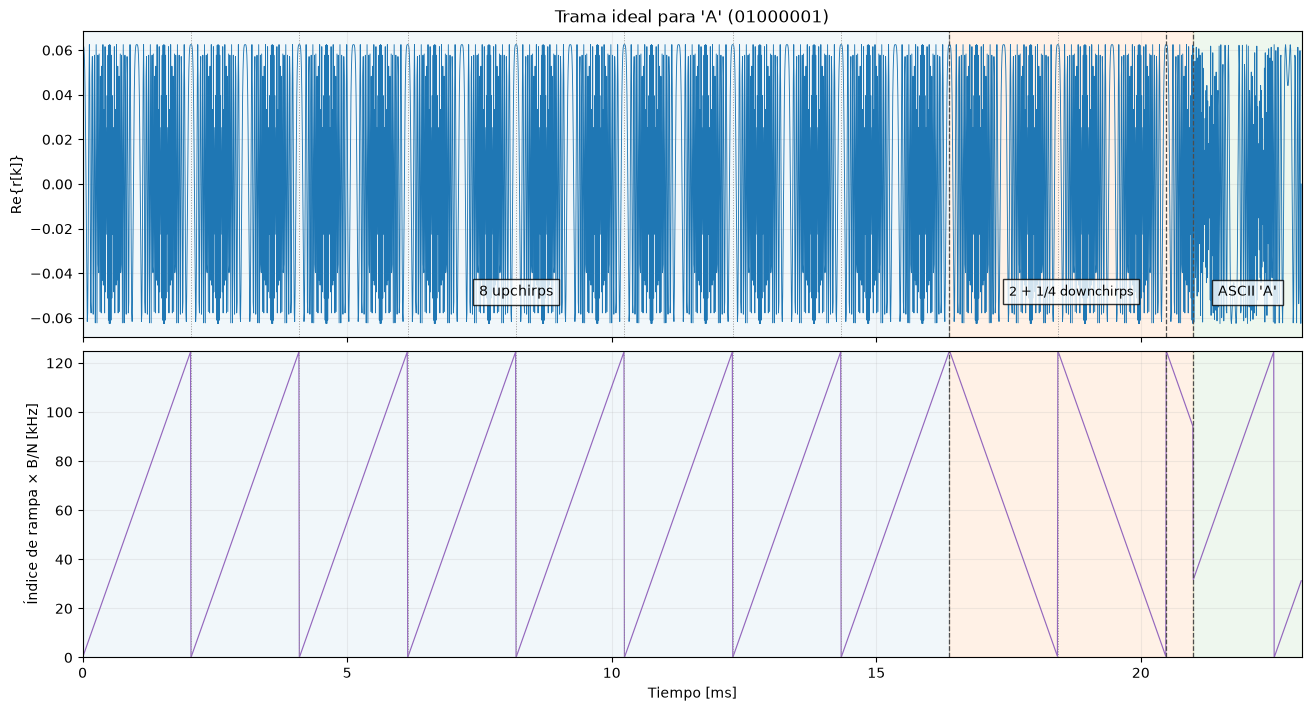

In [12]:
# Índice (s+k) mod N de la ecuación (3), expresado sobre la banda B.
rampa_up = k * B / N
rampa_down = B - rampa_up  # B y 0 son el mismo borde en frecuencia discreta
rampa_payload = np.mod(valor_ascii + k, N) * B / N
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N//4], rampa_payload))
assert len(rampa_trama) == len(recibida_ideal)
tiempo_ms = np.arange(len(recibida_ideal)) / B * 1e3

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, recibida_ideal.real, lw=0.65, color='tab:blue')
axes[0].set(ylabel='Re{r[k]}', title=f'Trama ideal para {caracter!r} ({bits_payload})')
axes[1].plot(tiempo_ms, rampa_trama / 1e3, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]')

for ax in axes:
    ax.axvspan(0, limites[1]/B*1e3, color='tab:blue', alpha=0.06)
    ax.axvspan(limites[1]/B*1e3, limites[3]/B*1e3, color='tab:orange', alpha=0.10)
    ax.axvspan(limites[3]/B*1e3, limites[4]/B*1e3, color='tab:green', alpha=0.08)
    for muestra in np.arange(N, 10*N, N):
        ax.axvline(muestra/B*1e3, color='0.6', ls=':', lw=0.7)
    for muestra in limites[1:-1]:
        ax.axvline(muestra/B*1e3, color='0.3', ls='--', lw=0.9)
    ax.grid(True, alpha=0.2)

axes[0].text(limites[1]/(2*B)*1e3, -0.05, '8 upchirps', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[1]+limites[3])/(2*B)*1e3, -0.05, '2 + 1/4 downchirps', ha='center', fontsize=9, bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[3]+limites[4])/(2*B)*1e3, -0.05, f'ASCII {caracter!r}', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[1].set_ylim(0, B/1e3)
axes[1].set_xlim(0, len(recibida_ideal)/B*1e3)
plt.show()

La trama queda en `recibida_ideal`, un vector complejo de **2880 muestras (23,040 ms)**. En una clase posterior se le puede agregar ruido y buscar el comienzo del preámbulo antes de intentar recuperar el byte.